# Proposed project: Hidden Solar, Visible Error: How much of NESO's demand forecast error comes from solar?

## Background
Solar forecast accuracy in Great Britain is well studied: machine learning improved NESO's day-ahead solar forecasts by 33% (Alan Turing Institute, 2019), satellite-based models cut short-term solar forecast error from 650 MW to 233 MW (Open Climate Fix, 2024), and national solar estimates carry about ±5% uncertainty from capacity data (Huxley, 2021). Earlier National Grid documents linked solar to demand forecast error without measuring its share: a 2014 project filing tied a rise of about 100 MW in afternoon demand error to solar growth, while noting the rise was "not solely due to" solar, and a review published by Ofgem in 2017 put day-ahead solar forecast error at 548 MW but warned that error sources cannot simply be added. Solar errors are often assumed to pass one-for-one into demand error, but this has not been tested. NESO's 2026 reports name solar as the largest influence on demand forecast accuracy without giving figures, and Open Climate Fix's claim of an 8% reduction in demand error has no published method. This project measures how much of NESO's day-ahead demand forecast error is explained by its solar forecast error.

## Aim
Measure how much of NESO's day-ahead demand forecast error is caused by its day-ahead solar forecast error, from April 2021 to October 2026.

## Objectives
1. **How much:** estimate the share of demand forecast error explained by solar forecast error, and how many MW of demand error each MW of solar error produces.
2. **When:** identify the seasons, hours and weather conditions where the effect is largest, and whether over- and under-forecasts of solar behave differently.
3. **What changed:** explain how the relationship has shifted over time, including why NESO's errors rose in 2026.

## Data
| Dataset | Use |
|---|---|
| NESO historic demand data, 2021-2026 | Actual demand and NESO's solar and wind output estimates |
| NESO day-ahead demand forecast performance | NESO's official day-ahead demand forecast |
| NESO embedded solar and wind forecast archive | NESO's day-ahead solar and wind forecasts (issued hourly) |
| Sheffield Solar PV_Live | Independent solar estimate, used as a check |
| Weather data (to add) | Temperature, for the machine learning model |

## Approach
1. **Build the table:** one row per half-hour, with demand, solar and wind forecast errors (done: 96,598 half-hours).
2. **Regression:** relate demand forecast error to solar forecast error by year, season and hour.
3. **Machine learning:** train a gradient boosting model to predict NESO's demand forecast error from solar error, wind error, temperature and calendar effects. Use SHAP values to split each error into contributions from each cause. Train on earlier years and test on later years.
4. **Change over time:** repeat the estimates over rolling three-month windows to track shifts, including in 2026.

## Early results (summer daytime, May to August)
- Every year shows a clear link: each MW of solar forecast error becomes 0.48-0.83 MW of demand forecast error.
- Solar error explains 21-43% of the variation in demand forecast error, depending on the year.
- Results are almost identical for forecasts issued at 08:00 or 10:00 the day before.
- Solar's share rose from about 27% (2021-22) to about 42% (2023-25), then fell to 21% in 2026, when NESO's overall error rose. This suggests the 2026 rise has a different cause.
- Initial observation, still to be tested: solar overforecasts pass into demand error almost one-for-one, while underforecasts pass through only about half.

## Why it matters
- Gives the first public measurement of a cause NESO itself identifies as its largest source of error.
- Offers an independent check of Open Climate Fix's unpublished claim that its solar forecast cut NESO's demand forecast error by 8%.
- Shows that NESO's published solar output estimate is Sheffield Solar's PV_Live rescaled to NESO's own capacity figure, so the two should not be treated as independent sources.

## Open items
- Formally test whether over- and under-forecasts of solar behave differently.
- Add temperature data for the machine learning model.
- Flag half-hours when NESO used its Demand Flexibility Service, which NESO adjusts for in its own metric.
- Complete the literature check before writing the introduction.
    

In [1]:
import pandas as pd


In [67]:
data = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\day_ahead_embedded_forecasts.csv")

In [68]:
data.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,wind_fc_08,solar_fc_08,issued_08,wind_fc_09,solar_fc_09,issued_09,wind_fc_10,solar_fc_10,issued_10,end_utc
0,2021-01-02,1,833,0.0,2021-01-01 07:12:00,879,0.0,2021-01-01 08:12:00,873,0.0,2021-01-01 09:12:00,2021-01-02 00:30:00+00:00
1,2021-01-02,2,825,0.0,2021-01-01 07:12:00,867,0.0,2021-01-01 08:12:00,867,0.0,2021-01-01 09:12:00,2021-01-02 01:00:00+00:00
2,2021-01-02,3,822,0.0,2021-01-01 07:12:00,867,0.0,2021-01-01 08:12:00,865,0.0,2021-01-01 09:12:00,2021-01-02 01:30:00+00:00
3,2021-01-02,4,818,0.0,2021-01-01 07:12:00,863,0.0,2021-01-01 08:12:00,863,0.0,2021-01-01 09:12:00,2021-01-02 02:00:00+00:00
4,2021-01-02,5,825,0.0,2021-01-01 07:12:00,863,0.0,2021-01-01 08:12:00,869,0.0,2021-01-01 09:12:00,2021-01-02 02:30:00+00:00


In [70]:
NESOdata_2021_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2021.csv")
NESOdata_2022_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2022.csv")
NESOdata_2023_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2023.csv")
NESOdata_2024_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2024.csv")
NESOdata_2025_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2025.csv")
NESOdata_2026_demand = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_demand_2026.csv")

In [74]:
NESO_demand_data = pd.concat([NESOdata_2021_demand,NESOdata_2022_demand,NESOdata_2023_demand,NESOdata_2024_demand,NESOdata_2025_demand, NESOdata_2026_demand])

In [75]:
NESO_demand_data.shape

(100942, 23)

In [76]:
pvlive_data= pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\pvlive_national.csv")

In [77]:
pvlive_data.shape

(101930, 5)

In [78]:
neso = NESO_demand_data.copy()

pv = pvlive_data.copy()

In [81]:
neso.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW,SCOTTISH_TRANSFER,FORECAST_ACTUAL_INDICATOR
0,01-JAN-2021,1,28354,28969,26130,1158,6527,0,13471,0,...,0,215,203,999,0,0,0,0,NaN,NaN
1,01-JAN-2021,2,28501,29114,26281,1208,6527,0,13471,0,...,0,359,203,999,0,0,0,0,NaN,NaN
2,01-JAN-2021,3,27759,28376,25557,1202,6527,0,13471,0,...,0,362,202,999,0,0,0,0,NaN,NaN
3,01-JAN-2021,4,26912,27749,24792,1226,6527,0,13471,0,...,0,361,203,1000,0,0,0,0,NaN,NaN
4,01-JAN-2021,5,26004,27178,23933,1193,6527,0,13471,0,...,0,304,203,1000,0,0,0,0,NaN,NaN


In [87]:
s = neso.SETTLEMENT_DATE.astype(str,copy=False)

In [88]:
s.info()

<class 'pandas.core.series.Series'>
Index: 100942 entries, 0 to 13293
Series name: SETTLEMENT_DATE
Non-Null Count   Dtype 
--------------   ----- 
100942 non-null  object
dtypes: object(1)
memory usage: 1.5+ MB


In [91]:
# NESO demand: settlement date + period -> UTC end of half-hour
s = neso.SETTLEMENT_DATE.astype(str)
d = pd.to_datetime(s.str[:10], format="%Y-%m-%d", errors="coerce")
for fmt in ["%d-%b-%Y", "%d-%b-%y", "%d/%m/%Y"]:      # 01-JAN-2021, 01-Jan-23, 01/01/2021
    d = d.fillna(pd.to_datetime(s.str.title(), format=fmt, errors="coerce"))
assert d.notna().all(), s[d.isna()].head()
mid = d.dt.tz_localize("Europe/London").dt.tz_convert("UTC")
neso["end_utc"] = mid + pd.to_timedelta(neso.SETTLEMENT_PERIOD * 30, unit="min")
neso = neso.drop_duplicates("end_utc", keep="last")

# PV_Live: already UTC, end of half-hour
pv["end_utc"] = pd.to_datetime(pv.datetime_gmt, utc=True)
pv = pv.drop_duplicates("end_utc").rename(columns={"generation_mw": "pvlive_solar_mw",
                                                   "installedcapacity_mwp": "pvlive_capacity_mwp"})

joined_data = neso.merge(pv[["end_utc", "pvlive_solar_mw", "pvlive_capacity_mwp"]],
                         on="end_utc", how="inner", validate="one_to_one")

print(len(joined_data), joined_data.end_utc.is_unique,
      (joined_data.end_utc.diff().dropna() != pd.Timedelta("30min")).sum())

100942 True 0


In [92]:
joined_data.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW,SCOTTISH_TRANSFER,FORECAST_ACTUAL_INDICATOR,end_utc,pvlive_solar_mw,pvlive_capacity_mwp
0,01-JAN-2021,1,28354,28969,26130,1158,6527,0,13471,0,...,999,0,0,0,0,NaN,NaN,2021-01-01 00:30:00+00:00,0.0,13503.179
1,01-JAN-2021,2,28501,29114,26281,1208,6527,0,13471,0,...,999,0,0,0,0,NaN,NaN,2021-01-01 01:00:00+00:00,0.0,13503.179
2,01-JAN-2021,3,27759,28376,25557,1202,6527,0,13471,0,...,999,0,0,0,0,NaN,NaN,2021-01-01 01:30:00+00:00,0.0,13503.179
3,01-JAN-2021,4,26912,27749,24792,1226,6527,0,13471,0,...,1000,0,0,0,0,NaN,NaN,2021-01-01 02:00:00+00:00,0.0,13503.179
4,01-JAN-2021,5,26004,27178,23933,1193,6527,0,13471,0,...,1000,0,0,0,0,NaN,NaN,2021-01-01 02:30:00+00:00,0.0,13503.179


In [95]:
joined_data.columns

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW',
       'GREENLINK_FLOW', 'SCOTTISH_TRANSFER', 'FORECAST_ACTUAL_INDICATOR',
       'end_utc', 'pvlive_solar_mw', 'pvlive_capacity_mwp'],
      dtype='object')

In [96]:
#dropping columns
drop_columns = [ 'TSD',
       'ENGLAND_WALES_DEMAND',
        'NON_BM_STOR', 
        'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 
       'IFA2_FLOW', 
       'BRITNED_FLOW', 
       'MOYLE_FLOW', 
       'EAST_WEST_FLOW',
       'NEMO_FLOW', 
       'NSL_FLOW', 
       'ELECLINK_FLOW',
       'VIKING_FLOW',
       'GREENLINK_FLOW',
       'SCOTTISH_TRANSFER', 
       'FORECAST_ACTUAL_INDICATOR']

act_data = joined_data.drop( columns = drop_columns, axis =1)

In [97]:
act_data.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,end_utc,pvlive_solar_mw,pvlive_capacity_mwp
0,01-JAN-2021,1,28354,1158,6527,0,13471,2021-01-01 00:30:00+00:00,0.0,13503.179
1,01-JAN-2021,2,28501,1208,6527,0,13471,2021-01-01 01:00:00+00:00,0.0,13503.179
2,01-JAN-2021,3,27759,1202,6527,0,13471,2021-01-01 01:30:00+00:00,0.0,13503.179
3,01-JAN-2021,4,26912,1226,6527,0,13471,2021-01-01 02:00:00+00:00,0.0,13503.179
4,01-JAN-2021,5,26004,1193,6527,0,13471,2021-01-01 02:30:00+00:00,0.0,13503.179


In [124]:
emb = data.copy()
#dfc = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_forecast_day_ahead_half_hourly_demand_forecast_performance.csv")

In [125]:
emb.shape

(102336, 12)

In [126]:
raw = pd.read_csv(r"C:\Users\HP\Desktop\BENV0091 Data analysis\Project stuff\raw_data\neso_forecast_day_ahead_half_hourly_demand_forecast_performance.csv")
print(raw[["Datetime", "Settlement_Period", "Demand_Forecast"]].head(3))

s = raw["Datetime"].astype(str)
d = pd.to_datetime(s.str[:10], format="%Y-%m-%d", errors="coerce")
for fmt in ["%d-%b-%Y", "%d-%b-%y", "%d/%m/%Y"]:
    d = d.fillna(pd.to_datetime(s.str.title(), format=fmt, errors="coerce"))
print("unparsed dates:", d.isna().sum())

mid = d.dt.tz_localize("Europe/London").dt.tz_convert("UTC")
raw["end_utc"] = mid + pd.to_timedelta(raw["Settlement_Period"] * 30, unit="min")
dups = raw[raw.end_utc.duplicated(keep=False)].sort_values("end_utc")
print("duplicate rows:", len(dups))
print(dups.head(10))

               Datetime  Settlement_Period  Demand_Forecast
0  2021-04-01T00:30:00Z                  1            21570
1  2021-04-01T01:00:00Z                  2            21130
2  2021-04-01T01:30:00Z                  3            21272
unparsed dates: 0
duplicate rows: 44
      Month        Date              Datetime  Settlement_Period  \
10225   Oct  2021-10-31  2021-10-31T01:00:00Z                  4   
10226   Oct  2021-10-31  2021-10-31T01:00:00Z                  4   
10227   Oct  2021-10-31  2021-10-31T01:30:00Z                  5   
10228   Oct  2021-10-31  2021-10-31T01:30:00Z                  5   
10223   Oct  2021-10-30  2021-10-31T00:00:00Z                 48   
10271   Oct  2021-10-31  2021-10-31T23:00:00Z                 48   
10273   Oct  2021-10-31  2021-11-01T00:00:00Z                 50   
10323   Nov  2021-11-02  2021-11-02T01:00:00Z                  2   
17281   Mar  2022-03-26  2022-03-27T00:00:00Z                 48   
17329   Mar  2022-03-28  2022-03-28T01:00:0

In [127]:
raw = raw.drop_duplicates("end_utc")

In [128]:
dfc=pd.DataFrame(raw)

In [129]:
dfc.head()

,Month,Date,Datetime,Settlement_Period,Demand_Forecast,Demand_Outturn,TRIAD_Avoidance_Estimate,TRIAD_Avoidance_Corrected_Demand_Outturn,APE,Absolute_Error,Publish_Datetime,end_utc
0,Apr,2021-04-01,2021-04-01T00:30:00Z,1,21570,19970,0,19970,8.0,1600,2021-03-31T09:45:00Z,2021-03-31 23:30:00+00:00
1,Apr,2021-04-01,2021-04-01T01:00:00Z,2,21130,20030,0,20030,5.5,1100,2021-03-31T09:45:00Z,2021-04-01 00:00:00+00:00
2,Apr,2021-04-01,2021-04-01T01:30:00Z,3,21272,20499,0,20499,3.8,773,2021-03-31T09:45:00Z,2021-04-01 00:30:00+00:00
3,Apr,2021-04-01,2021-04-01T02:00:00Z,4,21600,20940,0,20940,3.2,660,2021-03-31T09:45:00Z,2021-04-01 01:00:00+00:00
4,Apr,2021-04-01,2021-04-01T02:30:00Z,5,21478,20682,0,20682,3.8,796,2021-03-31T09:45:00Z,2021-04-01 01:30:00+00:00


In [123]:
dfc.columns

Index(['end_utc', 'demand_fc'], dtype='object')

In [130]:
# 1. Day-ahead solar and wind forecasts
emb["end_utc"] = pd.to_datetime(emb.end_utc, utc=True)
emb = emb.filter(regex="^(end_utc|solar_fc_|wind_fc_)")

# 2. NESO day-ahead demand forecast: replace the three CAPS names with the file's columns
mid = pd.to_datetime(dfc["Datetime"].astype(str).str[:10]).dt.tz_localize("Europe/London").dt.tz_convert("UTC")
dfc["end_utc"] = mid + pd.to_timedelta(dfc["Settlement_Period"] * 30, unit="min")
dfc = dfc.rename(columns={"Demand_Forecast": "demand_fc"})[["end_utc", "demand_fc"]]

# 3. Join
table = (joined_data
         .merge(dfc, on="end_utc", how="inner", validate="one_to_one")
         .merge(emb, on="end_utc", how="inner", validate="one_to_one"))
table = table[table.end_utc >= pd.Timestamp("2021-04-01", tz="UTC")]

# 4. Errors (positive = overforecast)
table["demand_err"] = table.demand_fc - table.ND
for h in ["08", "09", "10"]:
    table[f"solar_err_{h}"] = table[f"solar_fc_{h}"] - table.EMBEDDED_SOLAR_GENERATION
    table[f"wind_err_{h}"] = table[f"wind_fc_{h}"] - table.EMBEDDED_WIND_GENERATION

print(len(table), table.demand_err.abs().mean())

96598 658.1451996935755


In [133]:
print(table.end_utc.min(), table.end_utc.max(), table[["solar_err_09", "wind_err_09"]].isna().sum().to_dict())
print(table.demand_err.abs().groupby(table.end_utc.dt.year).mean().round(0))

2021-04-01 00:00:00+00:00 2026-10-04 23:00:00+00:00 {'solar_err_09': 0, 'wind_err_09': 0}
end_utc
2021    593.0
2022    638.0
2023    610.0
2024    637.0
2025    692.0
2026    796.0
Name: demand_err, dtype: float64


In [134]:
table.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,solar_fc_09,wind_fc_10,solar_fc_10,demand_err,solar_err_08,wind_err_08,solar_err_09,wind_err_09,solar_err_10,wind_err_10
1,01-APR-2021,2,19999,21438,18244,2095,6527,0,13642,0,...,0.0,1616,0.0,1131,0.0,-449,0.0,-449,0.0,-479
2,01-APR-2021,3,20482,21701,18745,2082,6527,0,13642,0,...,0.0,1616,0.0,790,0.0,-436,0.0,-456,0.0,-466
3,01-APR-2021,4,20926,21723,19183,2091,6527,0,13642,0,...,0.0,1581,0.0,674,0.0,-485,0.0,-485,0.0,-510
4,01-APR-2021,5,20685,21728,18945,2178,6527,0,13642,0,...,0.0,1581,0.0,793,0.0,-572,0.0,-558,0.0,-597
5,01-APR-2021,6,20333,21518,18550,2293,6527,0,13642,0,...,0.0,1612,0.0,659,0.0,-659,0.0,-659,0.0,-681


demand_err ~ solar_err_09 
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     -194.0203     24.452     -7.935      0.000    -241.946    -146.094
solar_err_09    -0.6405      0.027    -23.375      0.000      -0.694      -0.587
R2: 0.312 

demand_err ~ solar_err_09 + wind_err_09 
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     -196.0842     24.498     -8.004      0.000    -244.100    -148.068
solar_err_09    -0.6384      0.028    -22.820      0.000      -0.693      -0.584
wind_err_09     -0.4148      0.083     -4.972      0.000      -0.578      -0.251
R2: 0.323 

   year  slope     se     r2     n
0  2021 -0.722  0.064  0.289  2887
1  2022 -0.691  0.061  0.257  2966
2  2023 -0.791  0.059  0.420  2995
3  2024 -0.828  0.061  0.408  3019
4  2

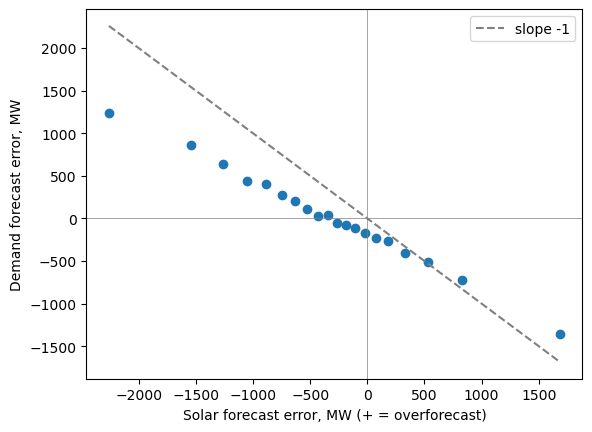

In [135]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

t = table.dropna(subset=["demand_err", "solar_err_09", "wind_err_09"]).copy()
t["day"] = t.end_utc.dt.date
summer = t[t.end_utc.dt.month.between(5, 8) & (t.EMBEDDED_SOLAR_GENERATION > 1000)]

def fit(df, formula="demand_err ~ solar_err_09"):
    # errors on the same day are related, so standard errors are clustered by day
    return smf.ols(formula, df).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(df.day)[0]})

# A. main test, and with wind as a control
for f in ["demand_err ~ solar_err_09", "demand_err ~ solar_err_09 + wind_err_09"]:
    m = fit(summer, f)
    print(f, "\n", m.summary().tables[1], "\nR2:", round(m.rsquared, 3), "\n")

# B. stability by year
rows = [(y, *[fit(g).params.solar_err_09, fit(g).bse.solar_err_09, fit(g).rsquared], len(g))
        for y, g in summer.groupby(summer.end_utc.dt.year)]
print(pd.DataFrame(rows, columns=["year", "slope", "se", "r2", "n"]).round(3))

# C. sensitivity to the forecast issue time
for h in ["08", "10"]:
    m = fit(summer, f"demand_err ~ solar_err_{h}")
    print(f"cut-off {h}:00  slope {m.params[f'solar_err_{h}']:.3f}  R2 {m.rsquared:.3f}")

# D. picture: average demand error in 20 bins of solar error
b = summer.groupby(pd.qcut(summer.solar_err_09, 20), observed=True)[["solar_err_09", "demand_err"]].mean()
plt.scatter(b.solar_err_09, b.demand_err)
plt.plot(b.solar_err_09, -b.solar_err_09, "--", c="grey", label="slope -1")
plt.axhline(0, c="grey", lw=0.5); plt.axvline(0, c="grey", lw=0.5)
plt.xlabel("Solar forecast error, MW (+ = overforecast)"); plt.ylabel("Demand forecast error, MW"); plt.legend(); plt.show()